# 05. Hybrid search, skor kecocokan, dan evaluasi akhir (Fase 5)

**Tujuan:** menggabungkan BM25 dan pencarian semantik dengan RRF, memberi skor kecocokan yang bisa dijelaskan,
lalu membandingkan semua metode E1 sampai E5 dengan jujur.

**Yang dipelajari:** Reciprocal Rank Fusion, pengaruh parameter `k`, skor kecocokan `0,40 S + 0,30 R + 0,20 E + 0,10 L`,
skill gap, dan membaca hasil evaluasi tanpa terlalu percaya diri.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # agar folder nlp_engine/ bisa diimpor
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from nlp_engine import *
from nlp_engine.preprocessing import normalize_text, tokenize, stem, STOPWORDS
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 160)
jobs, queries, qrels, ex = load_data("..")
job_ids = jobs.job_id.tolist()
print(f"{len(jobs)} lowongan, {len(queries)} kueri uji, {len(ex.names)} skill di kamus")

368 lowongan, 30 kueri uji, 56 skill di kamus


In [2]:
texts = job_text(jobs)
docs_tok = [preprocess(t, ex) for t in texts]
ix = InvertedIndex(docs_tok); bm25 = BM25(ix); tfidf = TfidfRetriever(ix); exact = ExactKeyword(texts)
sem = SemanticRetriever("auto")
sem.fit(texts if sem.requested == "sbert" else [" ".join(t) for t in docs_tok])
to_q = (lambda s: s) if sem.backend == "sbert" else (lambda s: " ".join(preprocess(s, ex)))
print("backend semantik:", sem.backend, sem.note)

backend semantik: lsa SBERT tidak tersedia (ModuleNotFoundError); memakai LSA.


## 1. RRF langkah demi langkah
Contoh dari rancangan proyek: empat lowongan, dua peringkat.

$$\text{RRF}(d)=\sum_{r}\frac{1}{k+\text{peringkat}_r(d)}\quad(k=60)$$

RRF memakai **peringkat**, bukan skor, jadi skor BM25 (tak berbatas) dan cosine (0 sampai 1) tak perlu disamakan skalanya.

In [3]:
toy_bm25 = {"Data Analyst": 1, "BI Analyst": 3, "Data Scientist": 2, "Backend Developer": 4}
toy_sbert = {"Data Analyst": 2, "BI Analyst": 1, "Data Scientist": 3, "Backend Developer": 4}
k = 60
toy = pd.DataFrame({"BM25": toy_bm25, "SBERT": toy_sbert})
toy["RRF"] = (1 / (k + toy["BM25"]) + 1 / (k + toy["SBERT"])).round(5)
toy.sort_values("RRF", ascending=False)

,BM25,SBERT,RRF
Data Analyst,1,2,0.03252
BI Analyst,3,1,0.03227
Data Scientist,2,3,0.03200
Backend Developer,4,4,0.03125


In [4]:
# hasil fungsi rrf() harus sama dengan hitungan manual di atas
order = rrf([["Data Analyst", "Data Scientist", "BI Analyst", "Backend Developer"],
             ["BI Analyst", "Data Analyst", "Data Scientist", "Backend Developer"]])
print(order)

['Data Analyst', 'BI Analyst', 'Data Scientist', 'Backend Developer']


## 2. Perbandingan E1 sampai E5

In [5]:
def hybrid(s, k=60, depth=30):
    return rrf([bm25.search(preprocess(s, ex), depth), sem.search(to_q(s), depth)], k=k, top=50)

systems = {
    "E1 Kata persis":        lambda s: exact.search(s, 50),
    "E2 TF-IDF + cosine":    lambda s: tfidf.search(preprocess(s, ex), 50),
    "E3 BM25":               lambda s: bm25.search(preprocess(s, ex), 50),
    f"E4 Semantik ({sem.backend})": lambda s: sem.search(to_q(s), 50),
    "E5 BM25 + semantik (RRF)": hybrid,
}
import time
table, perq = {}, {}
for name, fn in systems.items():
    t0 = time.perf_counter()
    summary, pq = evaluate_system(fn, queries, qrels, job_ids)
    summary["ms/kueri"] = round((time.perf_counter() - t0) * 1000 / len(queries), 2)
    table[name], perq[name] = summary, pq
res = pd.DataFrame(table).T
res

,P@5,Recall@10,MRR@10,NDCG@5,NDCG@10,ms/kueri
E1 Kata persis,0.873,0.747,1.000,0.858,0.764,0.38
E2 TF-IDF + cosine,0.893,0.847,0.944,0.839,0.803,0.46
E3 BM25,0.880,0.827,0.944,0.844,0.797,0.46
E4 Semantik (lsa),0.913,0.860,0.933,0.855,0.824,1.37
E5 BM25 + semantik (RRF),0.893,0.850,0.939,0.851,0.814,1.79


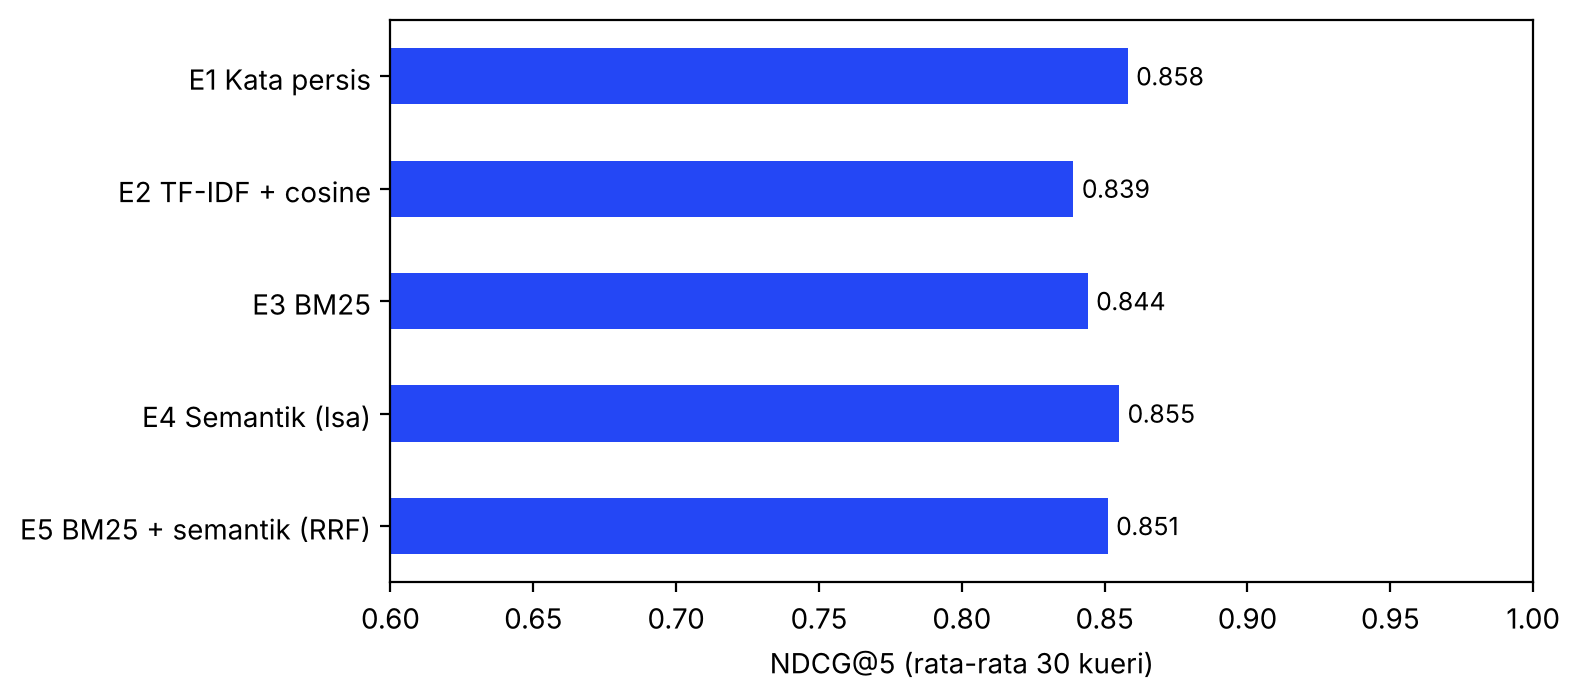

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
res["NDCG@5"].plot.barh(ax=ax, color="#2447F5")
ax.set_xlim(0.6, 1.0); ax.invert_yaxis(); ax.set_xlabel("NDCG@5 (rata-rata 30 kueri)")
for i, v in enumerate(res["NDCG@5"]): ax.text(v + .003, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

### Membaca tabel ini dengan jujur
- Ada 30 kueri, dan `qrels` dibuat otomatis dari label bidang. Selisih sekitar 0,01 sampai 0,02 sangat mungkin hanya kebetulan.
- Jangan menyimpulkan "hybrid selalu terbaik" dari satu tabel. Tabel ini menunjukkan metode mana yang unggul **pada dataset dan kueri ini**.
- Untuk menguji apakah selisih bermakna, bandingkan per kueri (di bawah) dan, bila perlu, lakukan uji berpasangan.

In [7]:
a, b = perq["E3 BM25"]["NDCG@5"], perq["E5 BM25 + semantik (RRF)"]["NDCG@5"]
diff = (b - a)
print(f"Hybrid lebih baik di {(diff > 0.01).sum()} kueri, lebih buruk di {(diff < -0.01).sum()}, setara di {(diff.abs() <= 0.01).sum()}")
print(f"Rata-rata selisih {diff.mean():+.3f}, simpangan baku {diff.std():.3f}, galat baku {diff.std()/np.sqrt(len(diff)):.3f}")
pd.DataFrame({"kueri": queries.set_index("query_id")["query"].str[:60], "selisih NDCG@5": diff.round(2)}).sort_values("selisih NDCG@5").iloc[[0, 1, 2, -3, -2, -1]]

Hybrid lebih baik di 7 kueri, lebih buruk di 6, setara di 17
Rata-rata selisih +0.007, simpangan baku 0.124, galat baku 0.023


,kueri,selisih NDCG@5
query_id,,
Q17,lulusan akuntansi cari kerja sebagai fresh graduate,-0.45
Q29,"saya punya skill Excel dan akuntansi, cari kerja di Surabaya",-0.18
Q07,Saya suka mendesain tampilan aplikasi dan bisa memakai Figma,-0.07
Q11,bisa jaringan komputer dan troubleshooting kantor,0.17
Q23,menyusun roadmap produk dan menentukan prioritas fitur,0.17
Q18,"mengurus arsip, surat menyurat, dan jadwal pimpinan",0.32


## 3. Pengaruh parameter RRF

In [8]:
rows = []
for k in [1, 10, 60, 100]:
    for depth in [10, 30, 50]:
        s, _ = evaluate_system(lambda x: hybrid(x, k=k, depth=depth), queries, qrels, job_ids)
        rows.append({"k": k, "kedalaman": depth, "NDCG@5": s["NDCG@5"]})
pd.DataFrame(rows).pivot(index="k", columns="kedalaman", values="NDCG@5")

kedalaman,10,30,50
k,,,
1,0.849,0.847,0.847
10,0.851,0.849,0.849
60,0.851,0.851,0.851
100,0.851,0.851,0.851


## 4. Skor kecocokan dan skill gap
Setelah kandidat ditemukan, tiap lowongan diberi skor `0,40 S + 0,30 R + 0,20 E + 0,10 L` lalu dijelaskan.
Bobot ini hipotesis awal. **Skor bukan peluang diterima kerja.**

In [9]:
query = "Saya menguasai Python, SQL, Pandas, dan visualisasi data. Saya sedang mencari pekerjaan untuk fresh graduate di bidang analisis data. Lokasi Jakarta."
u = understand_query(query, ex)
print("Dipahami sistem:", u)
cos = sem.scores(to_q(query))
cands = hybrid(query)[:10]
rows = []
for d in cands:
    m = match_job(jobs.iloc[d].to_dict(), u["skills"], cos[d], u["level"], u["location"])
    rows.append({"job_id": job_ids[d], "judul": jobs.job_title[d], "level": jobs.experience_level[d], "lokasi": jobs.location[d],
                 "skor": m["score"], "S": m["S"], "R": m["R"], "E": m["E"], "L": m["L"], "belum dimiliki": ", ".join(m["missing"])})
ranked = pd.DataFrame(rows).sort_values("skor", ascending=False).reset_index(drop=True)
ranked

Dipahami sistem: {'skills': ['Python', 'SQL', 'Pandas', 'Visualisasi Data', 'Analisis Data'], 'level': 1, 'location': 'Jakarta', 'employment_type': None}


,job_id,judul,level,lokasi,skor,S,R,E,L,belum dimiliki
0,J0331,Data Analyst (Fresh Graduate),Entry Level,Surabaya,61.7,57,51,100,35,Microsoft Excel
1,J0157,Reporting Analyst (Fresh Graduate),Entry Level,Surabaya,59.5,50,53,100,35,"Microsoft Excel, Power BI"
2,J0014,Data Analyst (Fresh Graduate),Entry Level,Bandung,59.3,52,49,100,35,"Microsoft Excel, Statistik"
3,J0306,Data Engineer,Junior,Jakarta,58.8,57,44,65,100,"ETL, Git, PostgreSQL, Docker"
4,J0178,Reporting Analyst (Fresh Graduate),Entry Level,Semarang,55.6,42,50,100,35,"Microsoft Excel, Power BI"
5,J0367,Reporting Analyst (Fresh Graduate),Entry Level,Semarang,55.5,42,50,100,35,"Microsoft Excel, Power BI"
6,J0146,Backend Developer (Fresh Graduate),Entry Level,Jakarta,53.3,25,44,100,100,"Django, PostgreSQL, Git"
7,J0083,Business Intelligence Analyst,Mid-level,Jakarta,47.8,57,35,27,88,"Power BI, Microsoft Excel"
8,J0066,Business Intelligence Analyst,Mid-level,Denpasar,39.2,52,34,25,30,"Power BI, Microsoft Excel, ETL"
9,J0273,HR Recruiter (Fresh Graduate),Entry Level,Jakarta,37.0,0,35,88,88,"Rekrutmen, Komunikasi, Microsoft Office"


In [10]:
best = ranked.iloc[0]; m = match_job(jobs[jobs.job_id == best.job_id].iloc[0].to_dict(), u["skills"], cos[job_ids.index(best.job_id)], u["level"], u["location"])
print(best["judul"], "-", best["skor"], "%")
print(m["explanation"])

Data Analyst (Fresh Graduate) - 61.7 %
Cocok karena SQL, Analisis Data sesuai dengan persyaratan. Skill belum dimiliki: Microsoft Excel.


Perhatikan bahwa urutan akhir (berdasarkan skor kecocokan) bisa berbeda dari urutan RRF. Itu disengaja: RRF mencari
*kandidat* yang relevan, sedangkan skor kecocokan menambahkan skill, level, dan lokasi pengguna.

> **Latihan 10.** Ubah bobot `WEIGHTS` di `nlp_engine/matching.py` (misalnya skill 0,5 dan relevansi 0,2). Bagaimana urutan
> hasilnya berubah? Bagaimana kamu akan memutuskan bobot yang benar tanpa data klik pengguna?

> **Latihan 11.** Dataset punya 8 posting ulang (`dup_of`). Cari tahu seberapa sering duplikat muncul bersama di 10 besar,
> lalu buat deteksi duplikat berbasis kemiripan cosine dan ukur precision/recall-nya terhadap kolom `dup_of`.

> **Latihan 12 (lanjutan, E6 dan E7).** Tambahkan reranking dengan cross-encoder pada 20 kandidat teratas. Untuk Learning to Rank (E7)
> kamu butuh penilaian relevansi dari manusia atau data klik. Jangan melatih model ranking dari skor yang dibuat sendiri.

## Ringkasan yang perlu dicatat untuk laporan
1. Dataset, `qrels`, dan kueri uji bersifat sintetis dan penilaiannya otomatis. Untuk artikel SINTA, buat penilaian manual pada sampel.
2. Laporkan backend semantik yang dipakai (SBERT atau LSA), model, dan parameter.
3. Laporkan jumlah kueri, metrik, dan ketidakpastiannya, bukan hanya rata-rata.